# Практическая работа 2. Двумерные массивы и изображения
## Самостоятельные и контрольные задания

Параметры всех заданий берутся из паспортов A–G (файл `lab02_2d_arrays_images_variants_v1`) по номеру варианта `VARIANT`. Чтобы получить решение для другого варианта, поменяйте номер в ячейке ниже и выполните блокнот заново (*Run All*).

In [ ]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

VARIANT = 1   # <--- номер вашего варианта (1..25)

In [10]:
# ВРУЧНУЮ ПРОПИСАННЫЕ ПАСПОРТА ДЛЯ ВАРИАНТА 1

# Паспорт A. Двумерный массив
A = {'n_rows': 4, 'n_cols': 6, 'a': 10, 'b': -1}

# Паспорт B. Изображение
B = {'H': 180, 'W': 280, 'bg': 0}

# Паспорт C. Точка
Cp = {'x': 57, 'y': 49, 'g': 120}

# Паспорт D. Отрезок
D = {'x1': 23, 'y1': 21, 'x2': 248, 'y2': 146, 'g': 140, 'thickness': 2}

# Паспорт E. Прямоугольник
E = {'x1': 24, 'y1': 22, 'x2': 89, 'y2': 72, 'g': 130, 'thickness': -1}

# Паспорт F. Окружность
F = {'x0': 122, 'y0': 90, 'R': 21, 'g': 150, 'thickness': -1}

# Паспорт G. Цвет OpenCV (B, G, R)
G = {'B': 0, 'G': 0, 'R': 255}

In [11]:
def show(img, title="", color=False):
    """Показ в блокноте. Полутона: фиксированная шкала 0..255."""
    plt.figure(figsize=(6, 4))
    if color:
        plt.imshow(img)
    else:
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
    plt.show()
    
print("Паспорта и функция show готовы к работе!")

Паспорта и функция show готовы к работе!


> Примечание: в методичке для быстрого просмотра используется `Image.fromarray(img).show()` (внешнее окно). В блокноте с готовыми результатами используется `plt.imshow`; строка `Image.fromarray(img).show()` работает так же и может быть добавлена в любую ячейку.

# Самостоятельные задания

## С1. Двумерный массив по формуле
Паспорт A: $m_{r,c}=ar+c+b$.

In [30]:
m = np.zeros((A["n_rows"], A["n_cols"]), dtype=int)
for r in range(A["n_rows"]):
    for c in range(A["n_cols"]):
        m[r, c] = A["a"] * r + c + A["b"]

print(m)
print(f"m[0,0] = {m[0,0]}")
print(f"m[1,2] = {m[1,2]}")
print(f"m[3,5] = {m[-1,-1]}")

[[-1  0  1  2  3  4]
 [ 9 10 11 12 13 14]
 [19 20 21 22 23 24]
 [29 30 31 32 33 34]]
m[0,0] = -1
m[1,2] = 11
m[3,5] = 34


## С2. Полутоновый холст и пиксель
Паспорта B и C. Пиксель $(x,y)$ записывается как `img[y, x]`.

img[y=49, x=57] = 120


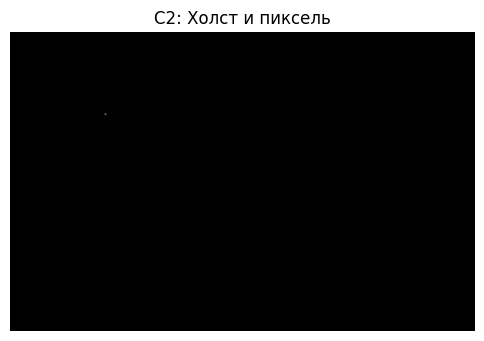

In [33]:
H, W = B["H"], B["W"]
x, y, g = Cp["x"], Cp["y"], Cp["g"]

img = np.zeros((H, W), dtype=np.uint8)
img[y, x] = g   # [y, x]!

print(f"img[y={y}, x={x}] = {img[y, x]}")
Image.fromarray(img).show()
show(img, "С2: Холст и пиксель")

## С3. Прямоугольная область
Паспорта B и E: залитый прямоугольник (a) срезом NumPy, (б) `cv2.rectangle(..., -1)`.

Совпадают: True


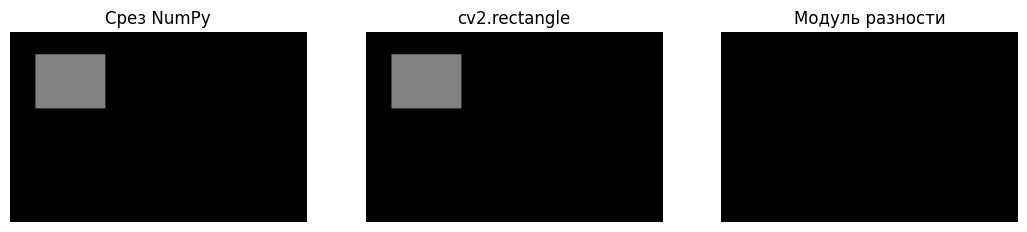

In [34]:
H, W, bg = B["H"], B["W"], B["bg"]
x1, y1, x2, y2, g = E["x1"], E["y1"], E["x2"], E["y2"], E["g"]

img_slice = np.full((H, W), bg, dtype=np.uint8)
img_slice[y1:y2+1, x1:x2+1] = g

img_cv = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(img_cv, (x1, y1), (x2, y2), g, -1)

diff = cv2.absdiff(img_slice, img_cv)
print("Совпадают:", np.array_equal(img_slice, img_cv))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axis, im, t in zip(ax, (img_slice, img_cv, diff), ("Срез NumPy", "cv2.rectangle", "Модуль разности")):
    axis.imshow(im, cmap="gray", vmin=0, vmax=255); axis.set_title(t); axis.axis("off")
plt.show()

## С4. Отрезок и окружность
Паспорта B, D и F на одном изображении.

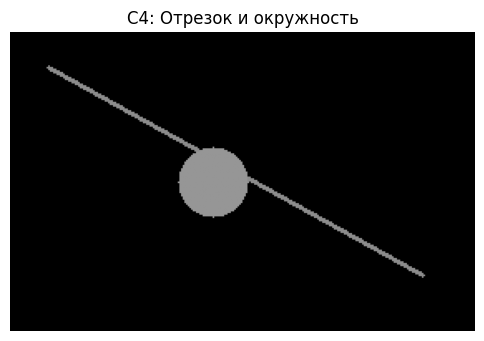

In [35]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)

cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])

show(img, "С4: Отрезок и окружность")

## С5. Составное изображение
Паспорта B, C, D, E, F: точка, отрезок, прямоугольник, окружность.

**Связь координат и индексов:** $x=c$ (столбец), $y=r$ (строка), поэтому точка $(x,y)$ — это `img[y, x]`. Функции OpenCV (`line`, `rectangle`, `circle`) принимают точки в порядке `(x, y)`.

Точка: (x,y)=(57,49) -> img[49, 57]


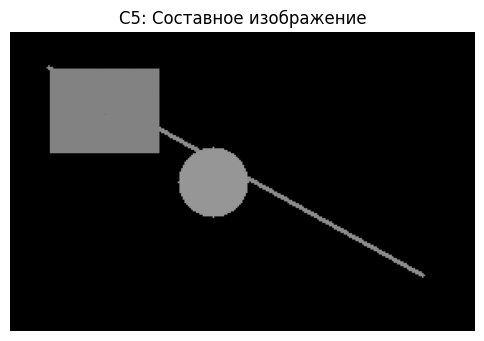

In [36]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)

cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
img[Cp["y"], Cp["x"]] = Cp["g"]

print(f"Точка: (x,y)=({Cp['x']},{Cp['y']}) -> img[{Cp['y']}, {Cp['x']}]")
show(img, "С5: Составное изображение")

## С6. Цвет OpenCV и PIL
Паспорта B, E, G: цветной прямоугольник; цвет в OpenCV задан как $(B,G,R)$, для PIL/Matplotlib нужно преобразование в RGB.

BGR: (0, 0, 255) -> RGB: (255, 0, 0)


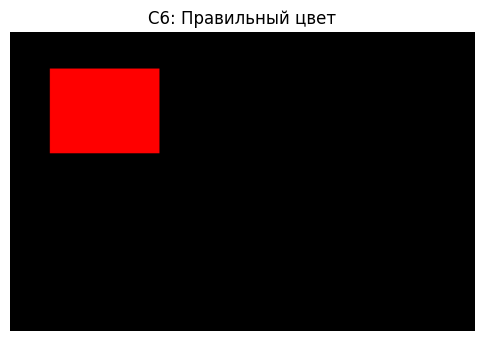

In [37]:
H, W = B["H"], B["W"]
color_bgr = (G["B"], G["G"], G["R"])

img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.rectangle(img_bgr, (E["x1"], E["y1"]), (E["x2"], E["y2"]), color_bgr, E["thickness"])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print(f"BGR: {color_bgr} -> RGB: {color_bgr[::-1]}")
show(img_rgb, "С6: Правильный цвет", color=True)

## И1. Интегральная полутоновая сцена
Паспорта B, D, E, F: все размеры и координаты из таблиц; результат проверяется.

Размер сцены: 180x280
Фон: 0
Уникальные яркости на изображении: [0, 130, 140, 150]


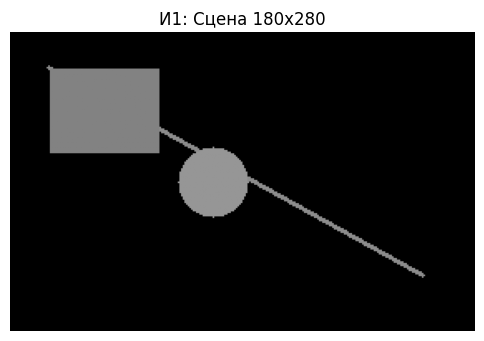

In [62]:
# И1. Интегральная полутоновая сцена
H, W, bg = B["H"], B["W"], B["bg"]

# 1. Создаем холст
img = np.full((H, W), bg, dtype=np.uint8)

# 2. Рисуем все примитивы (по конспекту)
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])

# 3. Выводим информацию
print(f"Размер сцены: {H}x{W}")
print(f"Фон: {bg}")
print("Уникальные яркости на изображении:", sorted(int(v) for v in np.unique(img)))

# 4. Показываем
show(img, f"И1: Сцена {H}x{W}")

## И2. Интегральная отладка
Паспорта B, C, G. Исходная программа содержала две ошибки:
1. индексы массива перепутаны с координатами: `img[x, y]` вместо `img[y, x]`;
2. BGR-массив передан в PIL/Matplotlib без преобразования в RGB.

Метка 5x5 вокруг (x,y)=(57,49); H=180, W=280
Центр метки при img[x, y]: (49, 57) (ожидалось (57, 49) )
Центр метки при img[y, x]: (57, 49)


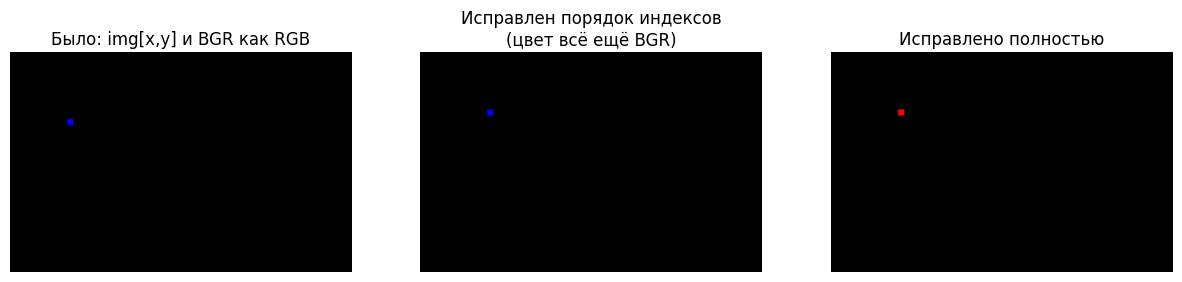

Цвет BGR (0, 0, 255) -> RGB (255, 0, 0)


In [64]:
# И2. Интегральная отладка
H, W = B["H"], B["W"]
x, y = Cp["x"], Cp["y"]
color_bgr = (G["B"], G["G"], G["R"])

def make_marker(wrong_index):
    img = np.zeros((H, W, 3), dtype=np.uint8)
    try:
        if wrong_index:
            # ОШИБКА 1: Перепутаны x и y (сначала столбец, потом строка)
            img[x - 2:x + 3, y - 2:y + 3] = color_bgr
        else:
            # ВЕРНО: сначала строка (y), потом столбец (x)
            img[y - 2:y + 3, x - 2:x + 3] = color_bgr
    except IndexError as e:
        print("IndexError:", e)
    return img

# Создаем две версии: с ошибкой и правильную
bad = make_marker(True)
good = make_marker(False)

print(f"Метка 5x5 вокруг (x,y)=({x},{y}); H={H}, W={W}")

# Функция для поиска центра метки
def center(im):
    yy, xx = np.nonzero(im.any(axis=2))
    return (int(xx.mean()), int(yy.mean())) if len(xx) else None

print("Центр метки при img[x, y]:", center(bad), "(ожидалось", (x, y), ")")
print("Центр метки при img[y, x]:", center(good))

# Показываем 3 варианта
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(bad);                                 ax[0].set_title("Было: img[x,y] и BGR как RGB")
ax[1].imshow(good);                                ax[1].set_title("Исправлен порядок индексов\n(цвет всё ещё BGR)")
ax[2].imshow(cv2.cvtColor(good, cv2.COLOR_BGR2RGB)); ax[2].set_title("Исправлено полностью")
for a_ in ax: a_.axis("off")
plt.show()
print("Цвет BGR", color_bgr, "-> RGB", color_bgr[::-1])

# Контрольные задания

## К1. Форма и индексация
Паспорт A.

In [40]:
r_idx, c_idx = np.indices((A["n_rows"], A["n_cols"]))
m = A["a"] * r_idx + c_idx + A["b"]
print(m)
print(f"m[1,2] = {m[1,2]}")

[[-1  0  1  2  3  4]
 [ 9 10 11 12 13 14]
 [19 20 21 22 23 24]
 [29 30 31 32 33 34]]
m[1,2] = 11


## К2. Ошибка индексации
Паспорта B и C. Найти и исправить `img[x, y]`.

Исправлено: img[49,57] = 120


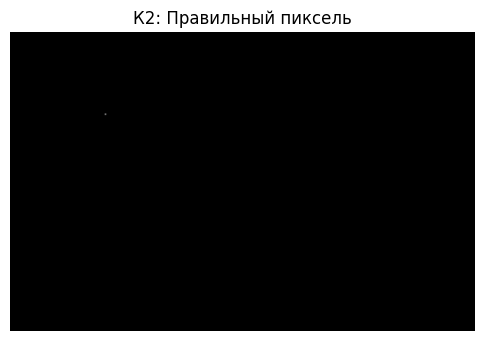

In [43]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
img[Cp["y"], Cp["x"]] = Cp["g"]
print(f"Исправлено: img[{Cp['y']},{Cp['x']}] = {img[Cp['y'], Cp['x']]}")
show(img, "К2: Правильный пиксель")

## К3. Полутоновое изображение
Паспорт B.

shape = (180, 280), dtype = uint8, min = 0, max = 0


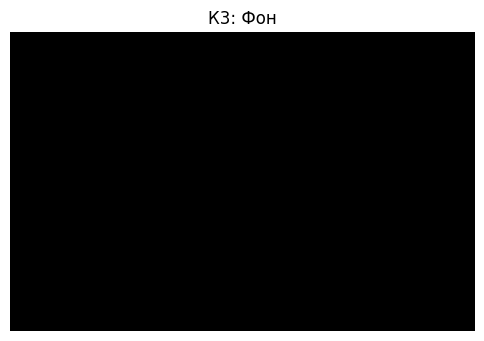

In [46]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
print(f"shape = {img.shape}, dtype = {img.dtype}, min = {img.min()}, max = {img.max()}")
show(img, "К3: Фон")

## К4. Пиксель по координатам
Паспорта B и C. Первый индекс — строка $=y$, второй — столбец $=x$.

Точка (57,49) -> img[49,57] = 120


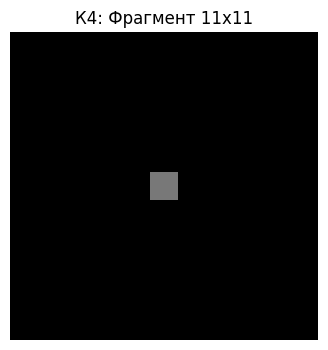

In [49]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
img[Cp["y"], Cp["x"]] = Cp["g"]
print(f"Точка ({Cp['x']},{Cp['y']}) -> img[{Cp['y']},{Cp['x']}] = {img[Cp['y'], Cp['x']]}")
y0, y1 = max(0, Cp["y"]-5), min(H, Cp["y"]+6)
x0, x1 = max(0, Cp["x"]-5), min(W, Cp["x"]+6)
show(img[y0:y1, x0:x1], "К4: Фрагмент 11x11")

## К5. Отрезок
Паспорта B и D.

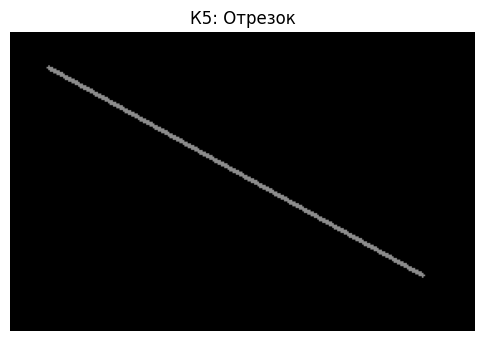

In [50]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
show(img, "К5: Отрезок")

## К6. Прямоугольник
Паспорта B и E (`thickness=-1` — заливка).

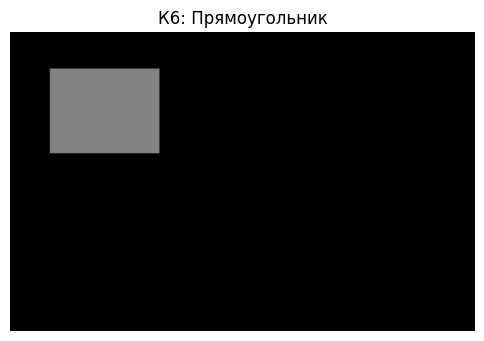

In [51]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
show(img, "К6: Прямоугольник")

## К7. Окружность
Паспорта B и F.

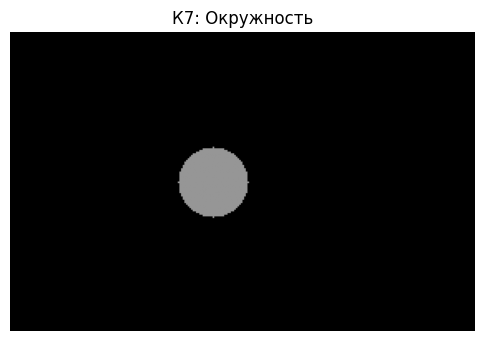

In [52]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
show(img, "К7: Окружность")

## К8. Срез или OpenCV
Паспорта B и E: одна область двумя способами.

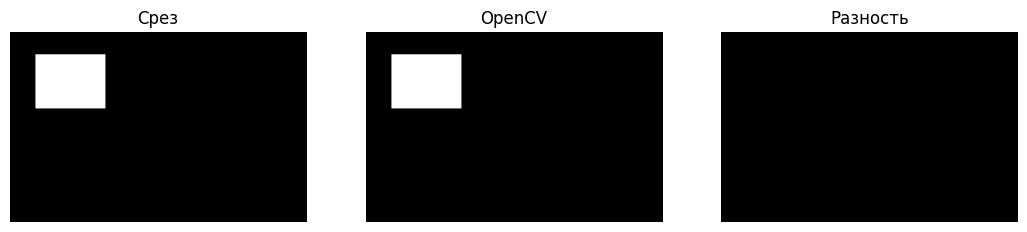

In [53]:
H, W, bg = B["H"], B["W"], B["bg"]
by_slice = np.full((H, W), bg, dtype=np.uint8)
by_slice[E["y1"]:E["y2"]+1, E["x1"]:E["x2"]+1] = E["g"]

by_cv = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(by_cv, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], -1)

diff = cv2.absdiff(by_slice, by_cv)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axis, im, t in zip(ax, (by_slice, by_cv, diff), ("Срез", "OpenCV", "Разность")):
    axis.imshow(im, cmap="gray"); axis.set_title(t); axis.axis("off")
plt.show()

## К9. Составная сцена
Паспорта B, D, E, F.

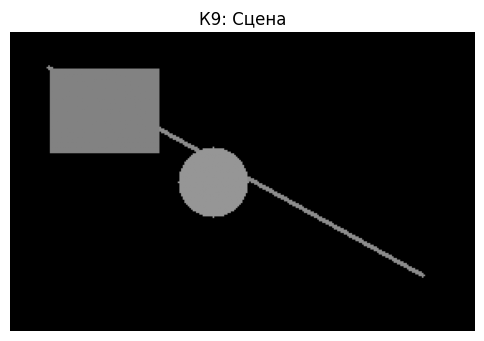

In [54]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
show(img, "К9: Сцена")

## К10. Проверка геометрии
Паспорта B, E, F: помещается ли фигура полностью в изображение. Допустимые координаты: $0\le x\le W-1$, $0\le y\le H-1$.

In [55]:
print(f"Прямоугольник x в [{E['x1']}, {E['x2']}], допустимо до {B['W']-1}")
print(f"Окружность x в [{F['x0']-F['R']}, {F['x0']+F['R']}], допустимо до {B['W']-1}")

Прямоугольник x в [24, 89], допустимо до 279
Окружность x в [101, 143], допустимо до 279


## К11. Цвет BGR/RGB
Паспорта B, E, G.

OpenCV (B,G,R) = (0, 0, 255)


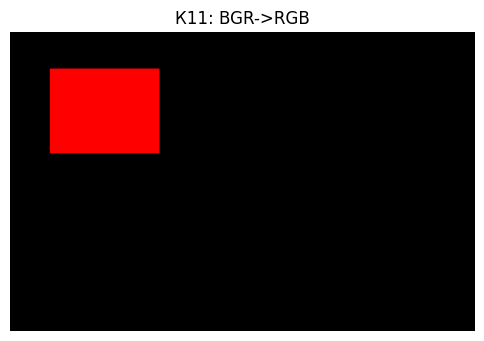

In [56]:
H, W = B["H"], B["W"]
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.rectangle(img_bgr, (E["x1"], E["y1"]), (E["x2"], E["y2"]), (G["B"], G["G"], G["R"]), E["thickness"])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print(f"OpenCV (B,G,R) = {(G['B'], G['G'], G['R'])}")
show(img_rgb, "К11: BGR->RGB", color=True)

## К12. Отладка цвета
Паспорта B, F, G. Причина неправильного цвета: массив в порядке BGR показан как RGB (красный и синий каналы поменялись местами).

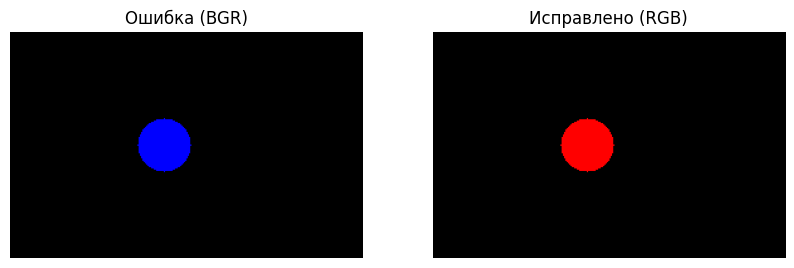

In [57]:
H, W = B["H"], B["W"]
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.circle(img_bgr, (F["x0"], F["y0"]), F["R"], (G["B"], G["G"], G["R"]), F["thickness"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img_bgr); ax[0].set_title("Ошибка (BGR)")
ax[1].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[1].set_title("Исправлено (RGB)")
for a_ in ax: a_.axis("off")
plt.show()